# Adversarial Robustness Evaluation & Multi-Layer Defense (PhishingGuard)

This notebook conducts **Problem-Space Adversarial Testing**, trains the **2-Stage Adversarial Defense** model, and exports the hardened deployment bundle directly to `Api/deploy_bundle.pkl`:
1. **Setup & Load Baseline Bundle** (`Backup/before_adversarial_defense_2026-11-23/Api/deploy_bundle.pkl`)
2. **SHAP Vulnerability Diagnosis:** Analyze feature-shielding shortcuts (`path_hyphens`, `num_query_params`) and URI parser/encoding vulnerabilities (`userinfo@`, Open Redirect, `%xx` encoding, Cyrillic/IDN Punycode Homograph `xn--`).
3. **Adversarial Test Suite (7 Scenarios A1 – A7):** Measure **Attack Success Rate (ASR)** across `N = 1,000` real Phishing URLs from `Data/Holdout/merged_holdout.csv` (`7,000` adversarial variants in total).
4. **Stage 1 Defense (Input Canonicalization + Layer-1 Guardrails + Cyrillic/IDN & Leetspeak De-obfuscation):** Integrated into `Api/features.py` and `Api/phishing_api.py`.
5. **Stage 2 Defense (Problem-Space Adversarial Retraining):** Augment `train.csv` with `59,994` adversarial phishing variants and retrain LightGBM (`544,373` total training samples).
6. **3-Stage Robustness Comparison & Clean Data Control:** Compare ASR, Mean Malicious Score, Clean Validation Split B (`N = 60,548`), and Benign Holdout FPR (`N = 1,000`).
7. **Export Hardened Bundle & Live API Verification:** Export `Api/deploy_bundle.pkl` and verify all adversarial scenarios (including Raw Cyrillic and IDN Punycode `xn--`).

## 1. Setup & Load Baseline Bundle

In [1]:
import sys
import os
import re
import math
import joblib
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.metrics import classification_report, f1_score, accuracy_score
from sklearn.model_selection import train_test_split
from urllib.parse import urlparse, parse_qs, unquote

# ── Đường dẫn — tính động theo thư mục làm việc hiện tại ──
BASE_DIR    = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'src' else os.getcwd()
API_DIR     = os.path.join(BASE_DIR, 'Api')
BACKUP_API  = os.path.join(BASE_DIR, 'Backup', 'before_adversarial_defense_2026-11-23', 'Api')
MODELS_DIR  = os.path.join(BASE_DIR, 'Models')
REPORTS_DIR = os.path.join(BASE_DIR, 'Reports')
IMAGES_DIR  = os.path.join(REPORTS_DIR, 'Images')
os.makedirs(IMAGES_DIR, exist_ok=True)
sys.path.insert(0, API_DIR)

from features import (
     FEATURE_NAMES, FEATURE_FUNCS, SUSPICIOUS_WORDS, SUSPICIOUS_TLDS, URL_SHORTENERS, _parse
)
from phishing_api import (
    TRUSTED_DOMAINS, MULTI_PART_TLDS, ABUSED_PLATFORM_DOMAINS, UNTRUSTED_HOST_EXCEPTIONS
)

# Nạp Baseline model từ bản sao lưu trước khi nâng cấp Defense (để luôn đối chiếu được Before vs After)
baseline_bundle_path = os.path.join(BACKUP_API, 'deploy_bundle.pkl')
if not os.path.isfile(baseline_bundle_path):
    baseline_bundle_path = os.path.join(API_DIR, 'deploy_bundle.pkl')

bundle    = joblib.load(baseline_bundle_path)
model     = bundle['model']
FEATS     = bundle['features']
TAU_HIGH  = bundle['tau_high']
TAU_LOW   = bundle['tau_low']
CLASSES   = bundle['classes']
BENIGN    = bundle['benign_idx']
explainer = shap.TreeExplainer(model)

print(f"BASE_DIR   : {BASE_DIR}")
print(f"API_DIR    : {API_DIR}")
print(f"IMAGES_DIR : {IMAGES_DIR}")
print(f"Loaded Baseline Bundle: k = {len(FEATS)} features | TAU_LOW = {TAU_LOW} | TAU_HIGH = {TAU_HIGH}")
print(f"Classes: {CLASSES} (BENIGN_IDX = {BENIGN})")

BASE_DIR   : d:\Study Assets\Final Project\PhishingGuard
API_DIR    : d:\Study Assets\Final Project\PhishingGuard\Api
IMAGES_DIR : d:\Study Assets\Final Project\PhishingGuard\Reports\Images
Loaded Baseline Bundle: k = 27 features | TAU_LOW = 0.58 | TAU_HIGH = 0.72
Classes: ['benign', 'defacement', 'malware', 'phishing'] (BENIGN_IDX = 0)


## 2. SHAP Vulnerability Diagnosis on Baseline v0.1

In [2]:
# Tái hiện hàm chuẩn hoá & trích xuất đặc trưng của Baseline v0.1 (trước khi vá lỗi)
_SCHEME_RE = re.compile(r'^(?:https?|ftp)://', re.IGNORECASE)
_WWW_RE    = re.compile(r'^www\d*\.', re.IGNORECASE)

def normalize_url_v01(url):
    u = str(url).strip()
    u = _SCHEME_RE.sub('', u)
    u = _WWW_RE.sub('', u)
    m = re.match(r'^([^/?#]*)(.*)$', u, flags=re.DOTALL)
    host, rest = m.group(1).lower(), m.group(2)
    if not rest or rest[0] in ('?', '#'):
        rest = '/' + rest
    return 'http://' + host + rest

def get_trusted_root_domain_v01(norm_url):
    host = _parse(norm_url).netloc.split(':')[0].lower().rstrip('.')
    if not host or host in UNTRUSTED_HOST_EXCEPTIONS:
        return None
    parts = host.split('.')
    if len(parts) < 2:
        return None
    root = '.'.join(parts[-3:]) if (len(parts) >= 3 and '.'.join(parts[-2:]) in MULTI_PART_TLDS) else '.'.join(parts[-2:])
    return root if root in TRUSTED_DOMAINS else None

def extract_features_v01(url):
    u = normalize_url_v01(url)
    d = _parse(u).netloc.split(':')[0].lower()
    feats = {name: func(u) for name, func in FEATURE_FUNCS}
    feats['domain_length']   = len(d)
    feats['domain_hyphens']  = d.count('-')
    feats['num_subdomains']  = max(0, len(d.split('.')) - 2)
    feats['is_suspicious_tld'] = int(d.split('.')[-1] in SUSPICIOUS_TLDS) if d else 0
    feats['has_suspicious_word'] = int(any(w in u.lower() for w in SUSPICIOUS_WORDS))
    return feats

def explain_single_url_baseline(url):
    norm_u = normalize_url_v01(url)
    tr = get_trusted_root_domain_v01(norm_u)
    if tr is not None:
        return {'url': url, 'norm': norm_u, 'score': 0.0, 'zone': 'green', 'whitelisted': True}
    f = extract_features_v01(url)
    X = pd.DataFrame([[f[k] for k in FEATS]], columns=FEATS, dtype=float)
    proba = model.predict_proba(X)[0]
    score = float(1.0 - proba[BENIGN])
    zone  = 'red' if score >= TAU_HIGH else ('yellow' if score >= TAU_LOW else 'green')
    sv = explainer.shap_values(X)
    b_shap = np.asarray(sv[BENIGN])[0] if isinstance(sv, list) else np.asarray(sv)[0, :, BENIGN]
    contrib = -b_shap
    order = np.argsort(contrib)[::-1]
    top_risk = [(FEATS[i], float(X.iloc[0, i]), round(float(contrib[i]), 3)) for i in order[:3]]
    top_safe = [(FEATS[i], float(X.iloc[0, i]), round(float(contrib[i]), 3)) for i in order[::-1][:2]]
    return {'url': url, 'norm': norm_u, 'score': round(score, 4), 'zone': zone,
            'whitelisted': False, 'top_risk_shap': top_risk, 'top_safe_shap': top_safe}

seed_cases = [
    'http://secure-login.paypal.com.verify-account.tk/signin?id=1',
    'http://vietcombank-secure-verify.xyz/login/account',
    'http://vietcombank-secure-verify.xyz/login/account/tin-tuc-cong-nghe-cap-nhat-he-thong-bao-mat-moi-2026',
    'http://facebook.com:80@vietcombank-secure-verify.xyz/login/account',
    'http://xn--pypal-4ve.com/',
]
for u in seed_cases:
    r = explain_single_url_baseline(u)
    print(f"[{r['zone'].upper():6s}] score={r['score']:.4f} | wl={r['whitelisted']} | {u}")
    if not r['whitelisted']:
        print(f"   + Đẩy về ĐỘC HẠI : {r['top_risk_shap']}")
        print(f"   - Đẩy về LÀNH TÍNH: {r['top_safe_shap']}")

[YELLOW] score=0.6339 | wl=False | http://secure-login.paypal.com.verify-account.tk/signin?id=1
   + Đẩy về ĐỘC HẠI : [('is_suspicious_tld', 1.0, 0.884), ('num_subdomains', 3.0, 0.244), ('domain_entropy', 4.1804, 0.221)]
   - Đẩy về LÀNH TÍNH: [('num_query_params', 1.0, -0.211), ('has_suspicious_word', 1.0, -0.207)]
[RED   ] score=0.8305 | wl=False | http://vietcombank-secure-verify.xyz/login/account
   + Đẩy về ĐỘC HẠI : [('is_suspicious_tld', 1.0, 1.002), ('domain_hyphens', 2.0, 0.303), ('domain_entropy', 4.1683, 0.114)]
   - Đẩy về LÀNH TÍNH: [('num_dots', 1.0, -0.074), ('has_suspicious_word', 1.0, -0.044)]
[GREEN ] score=0.1412 | wl=False | http://vietcombank-secure-verify.xyz/login/account/tin-tuc-cong-nghe-cap-nhat-he-thong-bao-mat-moi-2026
   + Đẩy về ĐỘC HẠI : [('is_suspicious_tld', 1.0, 0.781), ('domain_hyphens', 2.0, 0.219), ('domain_entropy', 4.1683, 0.088)]
   - Đẩy về LÀNH TÍNH: [('path_hyphens', 10.0, -2.418), ('path_length', 66.0, -0.492)]
[GREEN ] score=0.0000 | wl=True

## 3. Build 7-Scenario Adversarial Test Suite (A1 – A7) on Holdout Set

In [3]:
holdout_path = os.path.join(BASE_DIR, 'Data', 'Holdout', 'merged_holdout.csv')
df_holdout = pd.read_csv(holdout_path)
print("Holdout shape:", df_holdout.shape)

def predict_pipeline_baseline(urls, ml_model=model):
    rows, wl_flags = [], []
    for u in urls:
        nu = normalize_url_v01(u)
        try:
            tr = get_trusted_root_domain_v01(nu)
        except Exception:
            tr = None
        wl_flags.append(tr is not None)
        f = extract_features_v01(u)
        rows.append([f[k] for k in FEATS])
    X = pd.DataFrame(rows, columns=FEATS, dtype=float)
    proba = ml_model.predict_proba(X)
    ml_scores = 1.0 - proba[:, BENIGN]
    scores = np.where(wl_flags, 0.0, ml_scores)
    zones = ['green' if wl else ('red' if s >= TAU_HIGH else ('yellow' if s >= TAU_LOW else 'green'))
             for s, wl in zip(scores, wl_flags)]
    return scores, zones, wl_flags

# Lấy đúng N = 1,000 URL Phishing trong Holdout đã bị Baseline bắt được (zone in ['red', 'yellow'])
phish_pool = df_holdout[df_holdout['Label'] == 'phishing'].sample(n=4000, random_state=42)
p_scores, p_zones, _ = predict_pipeline_baseline(phish_pool['URL'].tolist())
det_mask = np.array([z in ('red', 'yellow') for z in p_zones])
detected_phish = phish_pool[det_mask].iloc[:1000].copy()
detected_phish['base_score'] = p_scores[det_mask][:1000]
detected_phish['base_zone']  = np.array(p_zones)[det_mask][:1000]

# Lấy thêm N = 1,000 URL Benign trong Holdout để kiểm soát tỷ lệ báo nhầm (FPR)
benign_holdout = df_holdout[df_holdout['Label'] == 'benign'].sample(n=1000, random_state=42).copy()
b_scores, b_zones, _ = predict_pipeline_baseline(benign_holdout['URL'].tolist())

# ── Định nghĩa 7 phép biến đổi tấn công trên không gian URL (Problem-Space Attacks A1 - A7) ──
def attack_A1_userinfo_port_spoof(u):
    nu = normalize_url_v01(u)
    return 'http://facebook.com:80@' + nu[len('http://'):]

def attack_A2_open_redirect(u):
    return 'https://www.google.com/url?q=' + u

def attack_A3_benign_slug_stuffing(u):
    p = _parse(normalize_url_v01(u))
    slug = '/tin-tuc-cong-nghe-cap-nhat-he-thong-bao-mat-moi-2026'
    q = ('?' + p.query) if p.query else ''
    return f"http://{p.netloc}{p.path.rstrip('/')}{slug}{q}"

def attack_A4_query_param_dilution(u):
    p = _parse(normalize_url_v01(u))
    return f"http://{p.netloc}{p.path}?page=home" if not p.query else f"http://{p.netloc}{p.path}?{p.query}&ref=aeiouaeiou"

def attack_A5_percent_encoding_obfuscation(u):
    p = _parse(normalize_url_v01(u))
    enc_path = ''.join(f"%{ord(c):02x}" if c.isalpha() else c for c in p.path)
    q = ('?' + p.query) if p.query else ''
    return f"http://{p.netloc}{enc_path}{q}"

def attack_A6_combined_camouflage(u):
    p = _parse(normalize_url_v01(u))
    slug = '/bai-viet-huong-dan-su-dung-dich-vu-truc-tuyen-2026'
    return f"http://{p.netloc}{p.path.rstrip('/')}{slug}?id=1"

def attack_A7_cyrillic_idn_homograph(u):
    p = _parse(normalize_url_v01(u))
    host = p.netloc.split(':')[0]
    parts = [seg for seg in host.split('.') if seg]
    main_label = parts[0] if len(parts) == 1 else parts[-2]
    cyr_map = {'a': 'а', 'e': 'е', 'o': 'о', 'i': 'і', 'c': 'с', 'p': 'р', 'x': 'х', 'y': 'у'}
    chars = list(main_label)
    replaced = False
    for idx, ch in enumerate(chars):
        if ch in cyr_map:
            chars[idx] = cyr_map[ch]
            replaced = True
            break
    if not replaced:
        chars.append('а')
    try:
        puny_label = ''.join(chars).encode('idna').decode('ascii')
    except Exception:
        puny_label = 'xn--' + main_label + '-4ve'
    return f"http://{puny_label}.com/"

attacks = {
    'A1: Userinfo+Port Spoofing':   attack_A1_userinfo_port_spoof,
    'A2: Trusted Open Redirect':    attack_A2_open_redirect,
    'A3: Benign SEO Slug Stuffing': attack_A3_benign_slug_stuffing,
    'A4: Query & Vowel Dilution':   attack_A4_query_param_dilution,
    'A5: URL Percent-Encoding':     attack_A5_percent_encoding_obfuscation,
    'A6: Combined Slug + Query':    attack_A6_combined_camouflage,
    'A7: Cyrillic / IDN Homograph': attack_A7_cyrillic_idn_homograph,
}

print(f"Tập mẫu Phishing gốc đã bị bắt: N = {len(detected_phish)} (Red: {(detected_phish['base_zone']=='red').sum()}, Yellow: {(detected_phish['base_zone']=='yellow').sum()})")
print(f"Điểm độc hại trung bình ban đầu: {detected_phish['base_score'].mean():.4f} (ASR ban đầu = 0.0%)")
print(f"Benign Holdout (N = 1000) Baseline -> Red FPR: {(np.array(b_zones)=='red').mean()*100:.2f}% | Green Rate: {(np.array(b_zones)=='green').mean()*100:.2f}%")

Holdout shape: (151369, 2)
Tập mẫu Phishing gốc đã bị bắt: N = 1000 (Red: 721, Yellow: 279)
Điểm độc hại trung bình ban đầu: 0.8386 (ASR ban đầu = 0.0%)
Benign Holdout (N = 1000) Baseline -> Red FPR: 0.40% | Green Rate: 97.60%


## 4. Stage 1 Defense: Canonicalization, Layer-1 Guardrails & Cyrillic/Leetspeak De-obfuscation

In [4]:
from features import (
    extract_features as extract_features_defended,
    normalize_url as normalize_url_defended,
    has_adversarial_userinfo,
    extract_nested_redirect_url,
    has_idn_homograph,
)
from phishing_api import get_trusted_root_domain as get_trusted_root_domain_defended

def predict_pipeline_defended(urls, ml_model=model):
    rows, wl_flags, guard_flags = [], [], []
    for u in urls:
        nu = normalize_url_defended(u)
        tr = get_trusted_root_domain_defended(nu, raw_url=u)
        wl_flags.append(tr is not None)
        f = extract_features_defended(u)
        guard_flags.append(has_adversarial_userinfo(u) or has_idn_homograph(u))
        rows.append([f[k] for k in FEATS])
    X = pd.DataFrame(rows, columns=FEATS, dtype=float)
    proba = ml_model.predict_proba(X)
    ml_scores = 1.0 - proba[:, BENIGN]
    ml_scores = np.where(guard_flags, np.maximum(ml_scores, TAU_HIGH), ml_scores)
    scores = np.where(wl_flags, 0.0, ml_scores)
    zones = ['green' if wl else ('red' if s >= TAU_HIGH else ('yellow' if s >= TAU_LOW else 'green'))
             for s, wl in zip(scores, wl_flags)]
    return scores, zones, wl_flags

print("Loaded Stage 1 Defense directly from Api/features.py & Api/phishing_api.py.")
demo_adv = [
    'http://facebook.com:80@vietcombank-secure-verify.xyz/login/account',
    'https://www.google.com/url?q=http://vietcombank-secure-verify.xyz/login/account',
    'http://vietcombank-secure-verify.xyz/%6c%6f%67%69%6e/%61%63%63%6f%75%6e%74',
    'http://p\u0430ypal.com/l\u043eg\u0456n',
    'http://xn--pypal-4ve.com/',
]
sc_d, zn_d, wl_d = predict_pipeline_defended(demo_adv, ml_model=model)
print("Demo Stage 1 trên các mẫu tấn công (bao gồm cả Raw Cyrillic và IDN Punycode xn--):")
for u, s, z, w in zip(demo_adv, sc_d, zn_d, wl_d):
    print(f"  [{z.upper():6s}] score={s:.4f} | wl={w} | {u}")

Loaded Stage 1 Defense directly from Api/features.py & Api/phishing_api.py.
Demo Stage 1 trên các mẫu tấn công (bao gồm cả Raw Cyrillic và IDN Punycode xn--):
  [RED   ] score=0.8305 | wl=False | http://facebook.com:80@vietcombank-secure-verify.xyz/login/account
  [RED   ] score=0.8305 | wl=False | https://www.google.com/url?q=http://vietcombank-secure-verify.xyz/login/account
  [RED   ] score=0.8305 | wl=False | http://vietcombank-secure-verify.xyz/%6c%6f%67%69%6e/%61%63%63%6f%75%6e%74
  [RED   ] score=0.7200 | wl=False | http://pаypal.com/lоgіn
  [RED   ] score=0.7200 | wl=False | http://xn--pypal-4ve.com/


## 5. Stage 2 Defense: Problem-Space Adversarial Retraining

In [5]:
train_df = pd.read_csv(os.path.join(MODELS_DIR, 'Train_Test', 'merged', 'train.csv'))
val_df   = pd.read_csv(os.path.join(MODELS_DIR, 'Train_Test', 'merged', 'val.csv'))

label_to_idx  = {c: i for i, c in enumerate(CLASSES)}
X_train_clean = train_df[FEATS].values.astype(float)
y_train_clean = train_df['Label'].map(label_to_idx).values

train_phish_urls = train_df[train_df['Label'] == 'phishing']['URL'].sample(n=20000, random_state=42).tolist()

SLUG_POOL = [
    '/tin-tuc-cong-nghe-cap-nhat-he-thong-bao-mat-moi-2026',
    '/bai-viet-huong-dan-su-dung-dich-vu-truc-tuyen-2026',
    '/blog-technology-security-update-announcement-2026',
    '/news-article-daily-finance-banking-report-today',
    '/khuyen-mai-uu-dai-khach-hang-than-thiet-nam-2026',
]
QUERY_POOL = [
    '?page=home', '?id=1', '?ref=aeiouaeiou',
    '?utm_source=newsletter&page=index', '?lang=vi&view=detail',
]

adv_train_rows = []
for idx_u, u in enumerate(train_phish_urls):
    p = _parse(normalize_url_defended(u))
    if not p.netloc:
        continue
    base_path = p.path.rstrip('/')
    slug  = SLUG_POOL[idx_u % len(SLUG_POOL)]
    q_add = QUERY_POOL[idx_u % len(QUERY_POOL)]
    u_slug  = f"http://{p.netloc}{base_path}{slug}" + (('?' + p.query) if p.query else '')
    u_query = f"http://{p.netloc}{p.path}{q_add}" if not p.query else f"http://{p.netloc}{p.path}?{p.query}&ref=aeiouaeiou"
    u_comb  = f"http://{p.netloc}{base_path}{slug}{q_add}"
    for u_adv in (u_slug, u_query, u_comb):
        f_adv = extract_features_defended(u_adv)
        adv_train_rows.append([f_adv[k] for k in FEATS])

X_adv_aug = np.array(adv_train_rows, dtype=float)
y_adv_aug = np.full(len(adv_train_rows), label_to_idx['phishing'], dtype=int)

X_train_stage2 = np.vstack([X_train_clean, X_adv_aug])
y_train_stage2 = np.concatenate([y_train_clean, y_adv_aug])
print(f"Training Stage 2 LightGBM on {len(X_train_stage2):,} samples ({len(X_train_clean):,} clean + {len(X_adv_aug):,} adversarial phishing variants)...")

lgbm_stage2 = clone(model)
lgbm_stage2.fit(pd.DataFrame(X_train_stage2, columns=FEATS), y_train_stage2)

# Đánh giá trên Validation Split B (cùng random_state=0 như explainability.ipynb)
X_val_all = val_df[FEATS].values.astype(float)
y_val_all = val_df['Label'].map(label_to_idx).values
ia, ib = train_test_split(np.arange(len(y_val_all)), test_size=0.5, stratify=y_val_all, random_state=0)
X_b = pd.DataFrame(X_val_all[ib], columns=FEATS)
y_b = y_val_all[ib]

pred_b_base = model.predict(X_b)
pred_b_st2  = lgbm_stage2.predict(X_b)
print("\n=== CLEAN VALIDATION SPLIT B (N = 60,548) ===")
print(f"Baseline Accuracy: {accuracy_score(y_b, pred_b_base):.4f} | Macro-F1: {f1_score(y_b, pred_b_base, average='macro'):.4f}")
print(f"Stage 2  Accuracy: {accuracy_score(y_b, pred_b_st2):.4f} | Macro-F1: {f1_score(y_b, pred_b_st2, average='macro'):.4f}")
print("\nStage 2 Classification Report on Validation Split B:")
print(classification_report(y_b, pred_b_st2, target_names=CLASSES, digits=4))

Training Stage 2 LightGBM on 544,373 samples (484,379 clean + 59,994 adversarial phishing variants)...

=== CLEAN VALIDATION SPLIT B (N = 60,548) ===
Baseline Accuracy: 0.8332 | Macro-F1: 0.8019
Stage 2  Accuracy: 0.8252 | Macro-F1: 0.7919

Stage 2 Classification Report on Validation Split B:
              precision    recall  f1-score   support

      benign     0.8264    0.9375    0.8784     39416
  defacement     0.8856    0.7115    0.7890      7625
     malware     0.9583    0.8283    0.8886      1887
    phishing     0.7459    0.5182    0.6116     11620

    accuracy                         0.8252     60548
   macro avg     0.8540    0.7489    0.7919     60548
weighted avg     0.8225    0.8252    0.8163     60548


## 6. 3-Stage Robustness Comparison (A1 – A7) & Visualization

=== 3-STAGE ADVERSARIAL ROBUSTNESS COMPARISON (N = 1,000 PHISHING URLS x 7 ATTACKS) ===
                       Attack  Base_Score  Base_ASR  Stage1_Score  Stage1_ASR  Stage2_Score  Stage2_ASR
  A1: Userinfo+Port Spoofing      0.0000     100.0        0.8557         0.7        0.8532         0.1
   A2: Trusted Open Redirect      0.0000     100.0        0.8274         2.3        0.8182         7.9
A3: Benign SEO Slug Stuffing      0.1810      93.1        0.1847        92.9        0.9702         0.3
  A4: Query & Vowel Dilution      0.5781      49.2        0.5768        49.4        0.8525         5.6
    A5: URL Percent-Encoding      0.5509      44.6        0.8346         1.0        0.8239         6.3
   A6: Combined Slug + Query      0.1737      93.1        0.1737        93.1        0.9927         0.0
A7: Cyrillic / IDN Homograph      0.5289      78.1        0.7231         0.0        0.7222         0.0

=== BENIGN HOLDOUT (N = 1,000) FALSE POSITIVE CONTROL ===
Baseline -> Red FPR: 0.40% |

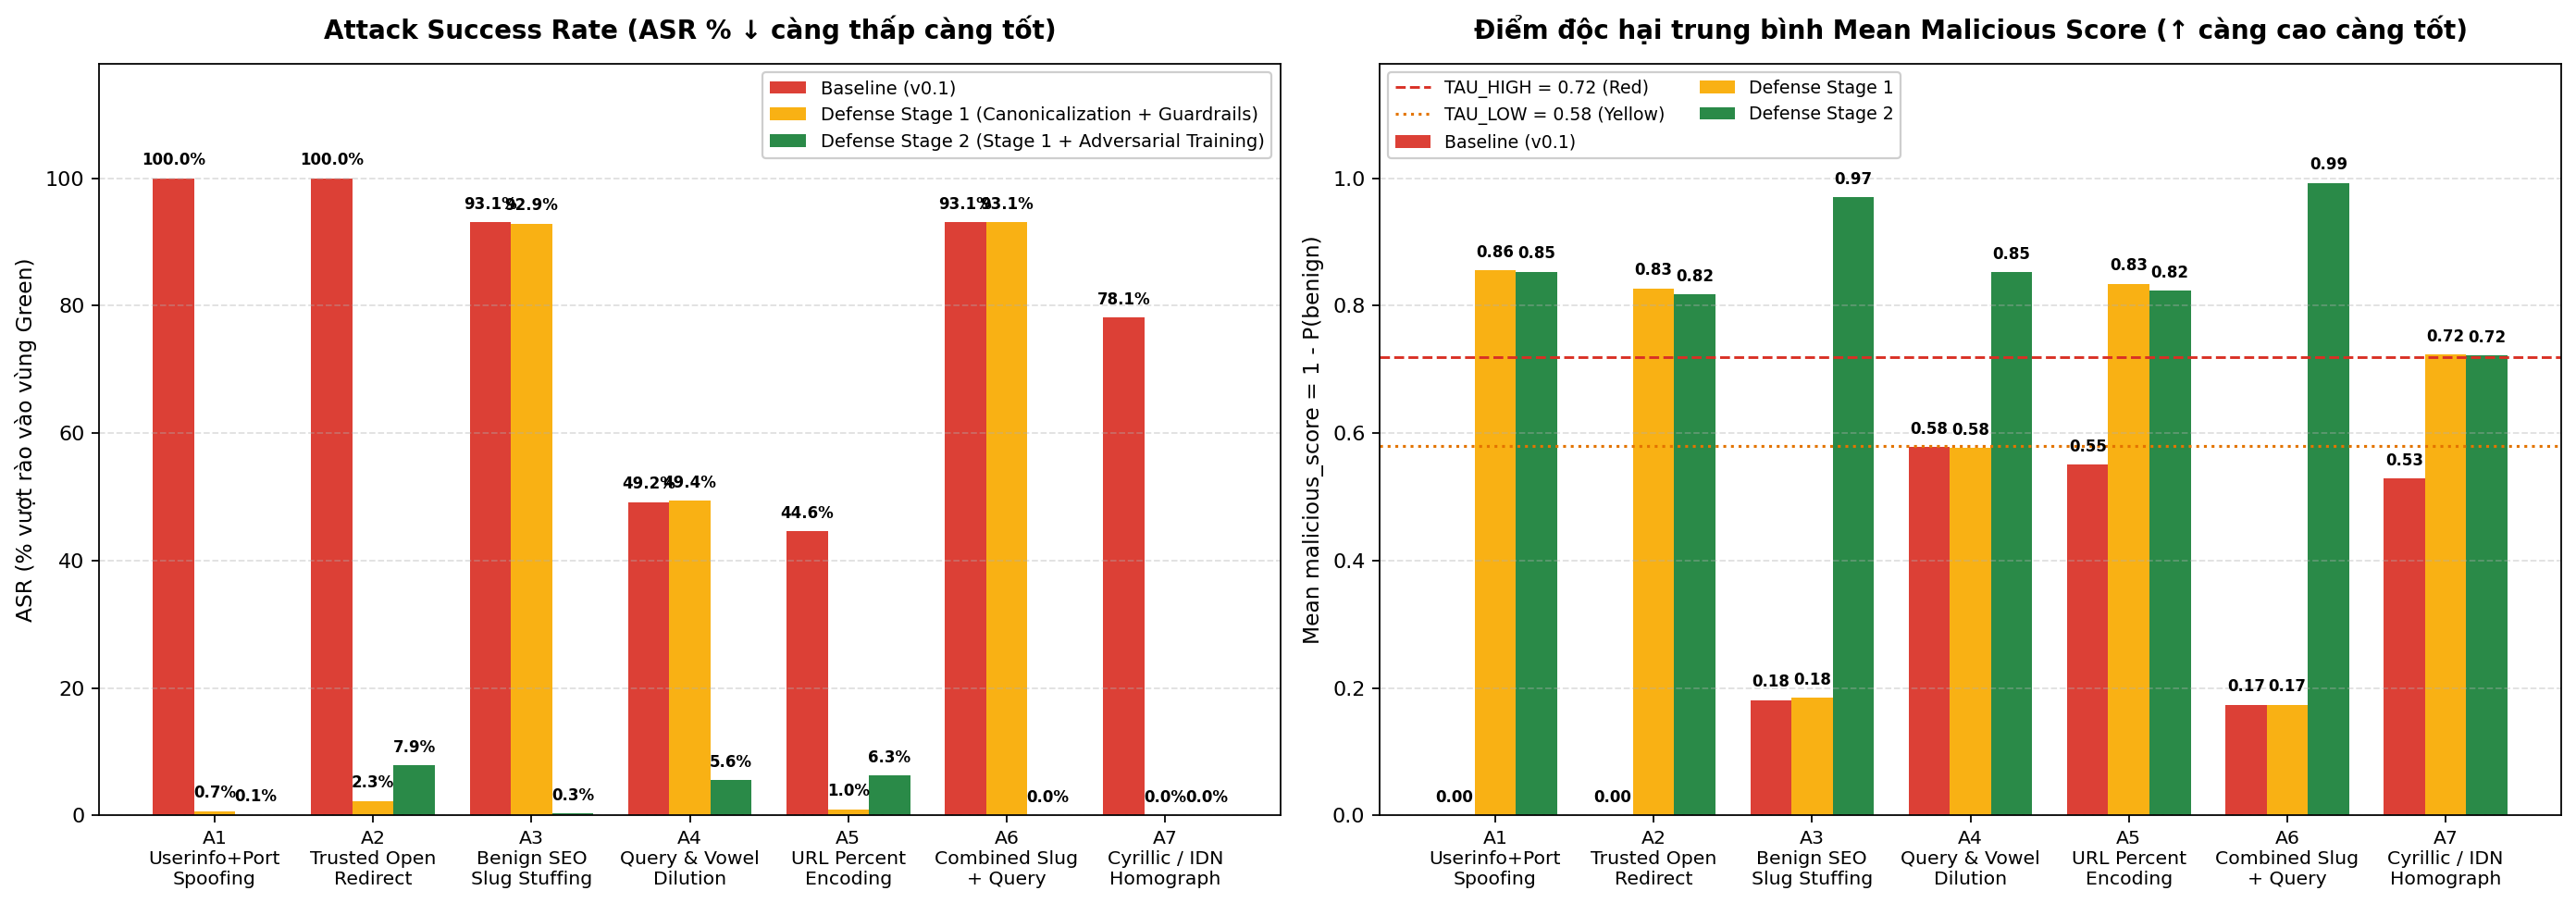

In [6]:
urls_1000 = detected_phish['URL'].tolist()
results_table = []

for name, fn in attacks.items():
    adv_urls = [fn(u) for u in urls_1000]
    sc_base, zn_base, _ = predict_pipeline_baseline(adv_urls, ml_model=model)
    sc_st1,  zn_st1,  _ = predict_pipeline_defended(adv_urls, ml_model=model)
    sc_st2,  zn_st2,  _ = predict_pipeline_defended(adv_urls, ml_model=lgbm_stage2)

    results_table.append({
        'Attack':       name,
        'Base_Score':   round(float(sc_base.mean()), 4),
        'Base_ASR':     round(sum(z == 'green' for z in zn_base) / 10.0, 1),
        'Stage1_Score': round(float(sc_st1.mean()), 4),
        'Stage1_ASR':   round(sum(z == 'green' for z in zn_st1)  / 10.0, 1),
        'Stage2_Score': round(float(sc_st2.mean()), 4),
        'Stage2_ASR':   round(sum(z == 'green' for z in zn_st2)  / 10.0, 1),
    })

df_res = pd.DataFrame(results_table)
print("=== 3-STAGE ADVERSARIAL ROBUSTNESS COMPARISON (N = 1,000 PHISHING URLS x 7 ATTACKS) ===")
print(df_res.to_string(index=False))

# Kiểm soát tỷ lệ báo nhầm (FPR) trên 1,000 URL Benign Holdout
b_sc_base, b_zn_base, _ = predict_pipeline_baseline(benign_holdout['URL'].tolist(), ml_model=model)
b_sc_st1,  b_zn_st1,  _ = predict_pipeline_defended(benign_holdout['URL'].tolist(), ml_model=model)
b_sc_st2,  b_zn_st2,  _ = predict_pipeline_defended(benign_holdout['URL'].tolist(), ml_model=lgbm_stage2)
print("\n=== BENIGN HOLDOUT (N = 1,000) FALSE POSITIVE CONTROL ===")
print(f"Baseline -> Red FPR: {(np.array(b_zn_base)=='red').mean()*100:.2f}% | Green Rate: {(np.array(b_zn_base)=='green').mean()*100:.2f}% | Mean Mal Score: {b_sc_base.mean():.4f}")
print(f"Stage 1  -> Red FPR: {(np.array(b_zn_st1)=='red').mean()*100:.2f}% | Green Rate: {(np.array(b_zn_st1)=='green').mean()*100:.2f}% | Mean Mal Score: {b_sc_st1.mean():.4f}")
print(f"Stage 2  -> Red FPR: {(np.array(b_zn_st2)=='red').mean()*100:.2f}% | Green Rate: {(np.array(b_zn_st2)=='green').mean()*100:.2f}% | Mean Mal Score: {b_sc_st2.mean():.4f}")

# Vẽ biểu đồ so sánh 3 giai đoạn trên 7 kịch bản (A1 - A7)
short_labels = [
    'A1\nUserinfo+Port\nSpoofing',
    'A2\nTrusted Open\nRedirect',
    'A3\nBenign SEO\nSlug Stuffing',
    'A4\nQuery & Vowel\nDilution',
    'A5\nURL Percent\nEncoding',
    'A6\nCombined Slug\n+ Query',
    'A7\nCyrillic / IDN\nHomograph',
]
fig, axes = plt.subplots(1, 2, figsize=(17.5, 6.2), dpi=160)
x = np.arange(len(df_res))
w = 0.26

ax = axes[0]
b1 = ax.bar(x - w, df_res['Base_ASR'],   width=w, label='Baseline (v0.1)', color='#d93025', alpha=0.92)
b2 = ax.bar(x,     df_res['Stage1_ASR'], width=w, label='Defense Stage 1 (Canonicalization + Guardrails)', color='#f9ab00', alpha=0.92)
b3 = ax.bar(x + w, df_res['Stage2_ASR'], width=w, label='Defense Stage 2 (Stage 1 + Adversarial Training)', color='#188038', alpha=0.92)
ax.set_title('Attack Success Rate (ASR % ↓ càng thấp càng tốt)', fontsize=12.5, fontweight='bold', pad=12)
ax.set_ylabel('ASR (% vượt rào vào vùng Green)', fontsize=10.5)
ax.set_xticks(x)
ax.set_xticklabels(short_labels, fontsize=9.2)
ax.set_ylim(0, 118)
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.legend(fontsize=8.8, loc='upper right', framealpha=0.95)
for bars in (b1, b2, b3):
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 1.5, f"{h:.1f}%", ha='center', va='bottom', fontsize=7.5, fontweight='bold')

ax2 = axes[1]
s1 = ax2.bar(x - w, df_res['Base_Score'],   width=w, label='Baseline (v0.1)', color='#d93025', alpha=0.92)
s2 = ax2.bar(x,     df_res['Stage1_Score'], width=w, label='Defense Stage 1', color='#f9ab00', alpha=0.92)
s3 = ax2.bar(x + w, df_res['Stage2_Score'], width=w, label='Defense Stage 2', color='#188038', alpha=0.92)
ax2.axhline(TAU_HIGH, color='#d93025', linestyle='--', linewidth=1.3, label=f'TAU_HIGH = {TAU_HIGH} (Red)')
ax2.axhline(TAU_LOW,  color='#e37400', linestyle=':',  linewidth=1.4, label=f'TAU_LOW = {TAU_LOW} (Yellow)')
ax2.set_title('Điểm độc hại trung bình Mean Malicious Score (↑ càng cao càng tốt)', fontsize=12.5, fontweight='bold', pad=12)
ax2.set_ylabel('Mean malicious_score = 1 - P(benign)', fontsize=10.5)
ax2.set_xticks(x)
ax2.set_xticklabels(short_labels, fontsize=9.2)
ax2.set_ylim(0, 1.18)
ax2.grid(axis='y', linestyle='--', alpha=0.4)
ax2.legend(fontsize=8.5, loc='upper left', ncol=2, framealpha=0.95)
for bars in (s1, s2, s3):
    for bar in bars:
        h = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2, h + 0.015, f"{h:.2f}", ha='center', va='bottom', fontsize=7.5, fontweight='bold')

plt.tight_layout()
out_img = os.path.join(IMAGES_DIR, 'adversarial_evaluation_comparison.png')
plt.savefig(out_img, bbox_inches='tight')
print(f"\nSaved figure to: {out_img}")
plt.show()

## 7. Export Hardened Deployment Bundle (`Api/deploy_bundle.pkl`) & Live API Verification

In [7]:
import importlib
import phishing_api

joblib.dump({
    'model': lgbm_stage2,
    'features': FEATS,
    'tau_high': TAU_HIGH,
    'tau_low': TAU_LOW,
    'classes': CLASSES,
    'benign_idx': BENIGN,
}, os.path.join(API_DIR, 'deploy_bundle.pkl'))
print("Exported hardened deploy_bundle.pkl to:", os.path.join(API_DIR, 'deploy_bundle.pkl'))

# Nạp lại phishing_api để kiểm thử trực tiếp endpoint predict() với bundle mới
importlib.reload(phishing_api)
print("\n── Live API Verification (5. Adversarial Evasion & Defense tests A1 - A8) ──")
adv_tests = [
    ('A1 Userinfo+Port Spoof',      'http://facebook.com:80@vietcombank-secure-verify.xyz/login/account'),
    ('A2 Trusted Open Redirect',    'https://www.google.com/url?q=http://vietcombank-secure-verify.xyz/login/account'),
    ('A3 Benign SEO Slug Stuffing', 'http://vietcombank-secure-verify.xyz/login/account/tin-tuc-cong-nghe-cap-nhat-he-thong-bao-mat-moi-2026'),
    ('A4 Query & Vowel Dilution',   'http://momo-wallet-authenticate.top/verify?page=home'),
    ('A5 URL Percent-Encoding',     'http://vietcombank-secure-verify.xyz/%6c%6f%67%69%6e/%61%63%63%6f%75%6e%74'),
    ('A6 Combined Slug + Query',    'http://vietcombank-secure-verify.xyz/login/account/bai-viet-huong-dan-su-dung-dich-vu-truc-tuyen-2026?id=1'),
    ('A7 Leetspeak Keyword Spoof',  'http://paypa1-secure-vcb.xyz/l0g1n/ver1fy'),
    ('A8a Raw Cyrillic Homograph',  'http://p\u0430ypal.com/l\u043eg\u0456n'),
    ('A8b IDN Punycode Homograph',  'http://xn--pypal-4ve.com/'),
]
for name, u in adv_tests:
    r = phishing_api.predict(phishing_api.Req(url=u))
    caught = r['zone'] in ('red', 'yellow') and not r.get('whitelisted', False)
    tag = 'CAUGHT' if caught else 'BYPASSED!'
    print(f"[{tag:9s}] {r['malicious_score']:.4f}  {r['zone']:6s}  {name:28s} | {r.get('normalized_url')}")

Exported hardened deploy_bundle.pkl to: d:\Study Assets\Final Project\PhishingGuard\Api\deploy_bundle.pkl

── Live API Verification (5. Adversarial Evasion & Defense tests A1 - A8) ──
[CAUGHT   ] 0.7962  red     A1 Userinfo+Port Spoof       | http://vietcombank-secure-verify.xyz/login/account
[CAUGHT   ] 0.7962  red     A2 Trusted Open Redirect     | http://vietcombank-secure-verify.xyz/login/account
[CAUGHT   ] 0.9879  red     A3 Benign SEO Slug Stuffing  | http://vietcombank-secure-verify.xyz/login/account/tin-tuc-cong-nghe-cap-nhat-he-thong-bao-mat-moi-2026
[CAUGHT   ] 0.9390  red     A4 Query & Vowel Dilution    | http://momo-wallet-authenticate.top/verify?page=home
[CAUGHT   ] 0.7962  red     A5 URL Percent-Encoding      | http://vietcombank-secure-verify.xyz/login/account
[CAUGHT   ] 0.9945  red     A6 Combined Slug + Query     | http://vietcombank-secure-verify.xyz/login/account/bai-viet-huong-dan-su-dung-dich-vu-truc-tuyen-2026?id=1
[CAUGHT   ] 0.7881  red     A7 Leetspeak Keyw